# Лабораторная работа №2

## Построение базовой ML-модели и проверка устойчивости входов

**Направление:** NLP

**Проект:** Prompt Injection Detection System

**Модель:** TF-IDF + Logistic Regression

**Датасет:** S-Labs/prompt-injection-dataset

**Цель:** обучить базовую модель обнаружения prompt injection-атак, оценить качество классификации и исследовать устойчивость модели к изменениям входных данных.

Используются очищенные выборки из каталога `data/processed/`, между которыми отсутствуют точные совпадения текстов.

Для воспроизводимости используется `random_state=42`. Предобработка TF-IDF обучается исключительно на Train. Validation используется для оценки при разработке, Test — для итоговой оценки после фиксации модели.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import time
import sklearn

from pathlib import Path

ROOT = Path("..")
DATA_DIR = ROOT / "data" / "processed"

train = pd.read_csv(DATA_DIR / "train.csv")
validation = pd.read_csv(DATA_DIR / "validation.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)
print("scikit-learn:", sklearn.__version__)

display(train.head())

Train: (11050, 2)
Validation: (1981, 2)
Test: (2101, 2)
scikit-learn: 1.9.1


,text,label
0,Can you explain the event loop in Node.js?,0
1,Instructions to ignore: none. New instructions...,1
2,What is the tallest waterfall in the world,0
3,How is chocolate made from cacao,0
4,What is the difference between annual and pere...,0


In [2]:
for name, df in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(f"\n{name}")
    print("Objects:", len(df))
    print("Missing values:", df.isna().sum().sum())
    print("Duplicate texts:", df["text"].duplicated().sum())
    print("Classes:")
    print(df["label"].value_counts().sort_index())

train_texts = set(train["text"])
val_texts = set(validation["text"])
test_texts = set(test["text"])

print("\nOverlaps:")
print("Train / Validation:", len(train_texts & val_texts))
print("Train / Test:", len(train_texts & test_texts))
print("Validation / Test:", len(val_texts & test_texts))


Train
Objects: 11050
Missing values: 0
Duplicate texts: 0
Classes:
label
0    6267
1    4783
Name: count, dtype: int64

Validation
Objects: 1981
Missing values: 0
Duplicate texts: 0
Classes:
label
0    1040
1     941
Name: count, dtype: int64

Test
Objects: 2101
Missing values: 0
Duplicate texts: 0
Classes:
label
0    1050
1    1051
Name: count, dtype: int64

Overlaps:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

SEED = 42

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=30000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        class_weight="balanced",
        random_state=SEED
    ))
])

X_train = train["text"]
y_train = train["label"]

X_val = validation["text"]
y_val = validation["label"]

start = time.perf_counter()

model.fit(X_train, y_train)

training_time = time.perf_counter() - start

print(f"Training time: {training_time:.4f} seconds")
print("Model successfully trained")

Training time: 1.2998 seconds
Model successfully trained


In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

val_pred = model.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Precision:", round(precision_score(y_val, val_pred), 4))
print("Recall:", round(recall_score(y_val, val_pred), 4))
print("F1:", round(f1_score(y_val, val_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_val,
    val_pred,
    target_names=["BENIGN", "INJECTION"],
    zero_division=0
))

Accuracy: 0.9783
Precision: 0.9828
Recall: 0.9713
F1: 0.977

Classification report:
              precision    recall  f1-score   support

      BENIGN       0.97      0.98      0.98      1040
   INJECTION       0.98      0.97      0.98       941

    accuracy                           0.98      1981
   macro avg       0.98      0.98      0.98      1981
weighted avg       0.98      0.98      0.98      1981



In [5]:
import json

with open("../metrics/baseline.json", encoding="utf-8") as f:
    baseline = json.load(f)

print("TEST RESULTS")
print("Model:", baseline["model"])
print("Test size:", baseline["test_size"])
print("Primary metric:", baseline["primary_metric"])

print("\nTest metrics:")
for name, value in baseline["test_metrics"].items():
    print(f"{name}: {value:.4f}")

print("\nFalse positives:", baseline["false_positives"])
print("False negatives:", baseline["false_negatives"])

TEST RESULTS
Model: TF-IDF + Logistic Regression
Test size: 2101
Primary metric: f1_injection

Test metrics:
accuracy: 0.9553
precision: 0.9908
recall: 0.9191
f1: 0.9536

False positives: 9
False negatives: 85


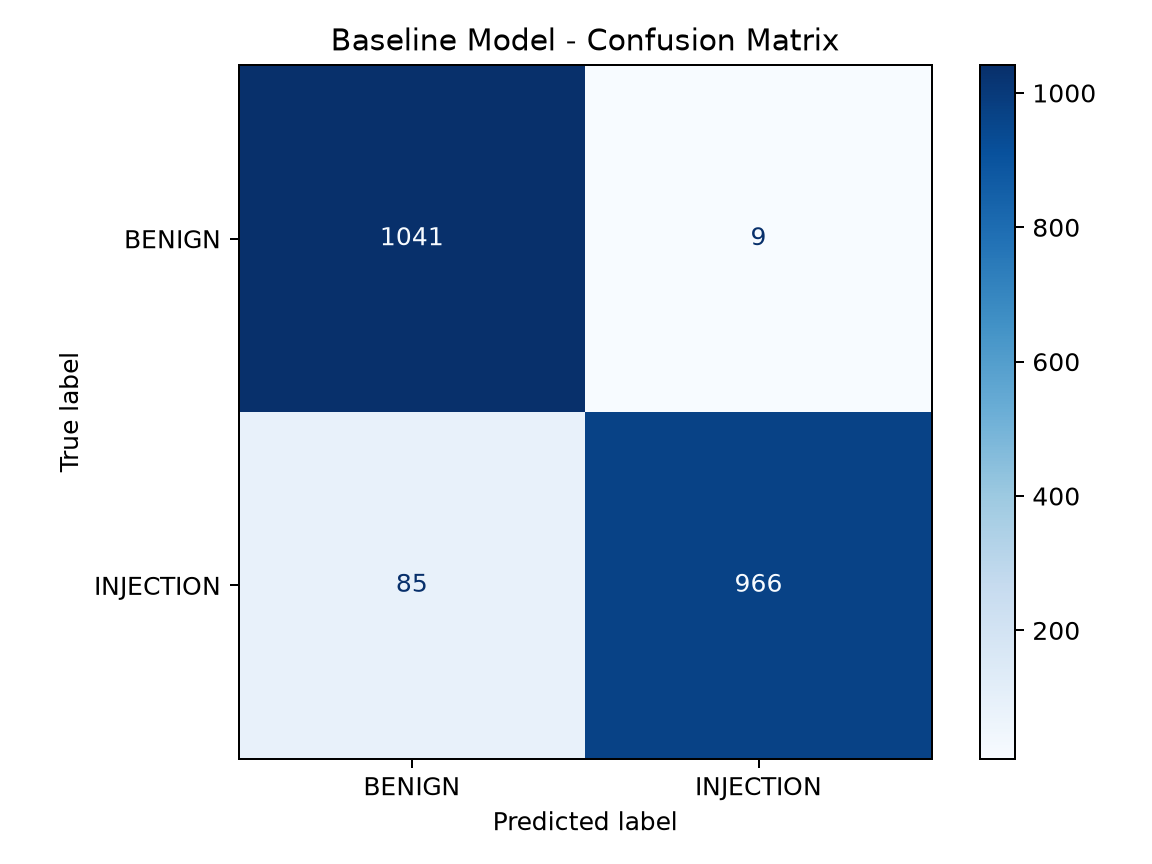

In [6]:
from IPython.display import Image, display

display(
    Image(filename="../metrics/confusion_matrix.png")
)

In [7]:
import json
import pandas as pd

with open("../metrics/robustness.json", encoding="utf-8") as f:
    robustness = json.load(f)

rows = []

for name, result in robustness["transformations"].items():
    rows.append({
        "Изменение": name,
        "Изменилось предсказаний": result["changed_predictions"],
        "Flip rate (%)": result["flip_rate"] * 100,
        "Accuracy до (%)": result["original_accuracy"] * 100,
        "Accuracy после (%)": result["modified_accuracy"] * 100,
        "Recall после (%)": result["modified_recall_injection"] * 100
    })

display(pd.DataFrame(rows).round(2))

,Изменение,Изменилось предсказаний,Flip rate (%),Accuracy до (%),Accuracy после (%),Recall после (%)
0,case_change,0,0.0,95.0,95.0,100.0
1,extra_spaces,0,0.0,95.0,95.0,100.0
2,typo,0,0.0,95.0,95.0,100.0


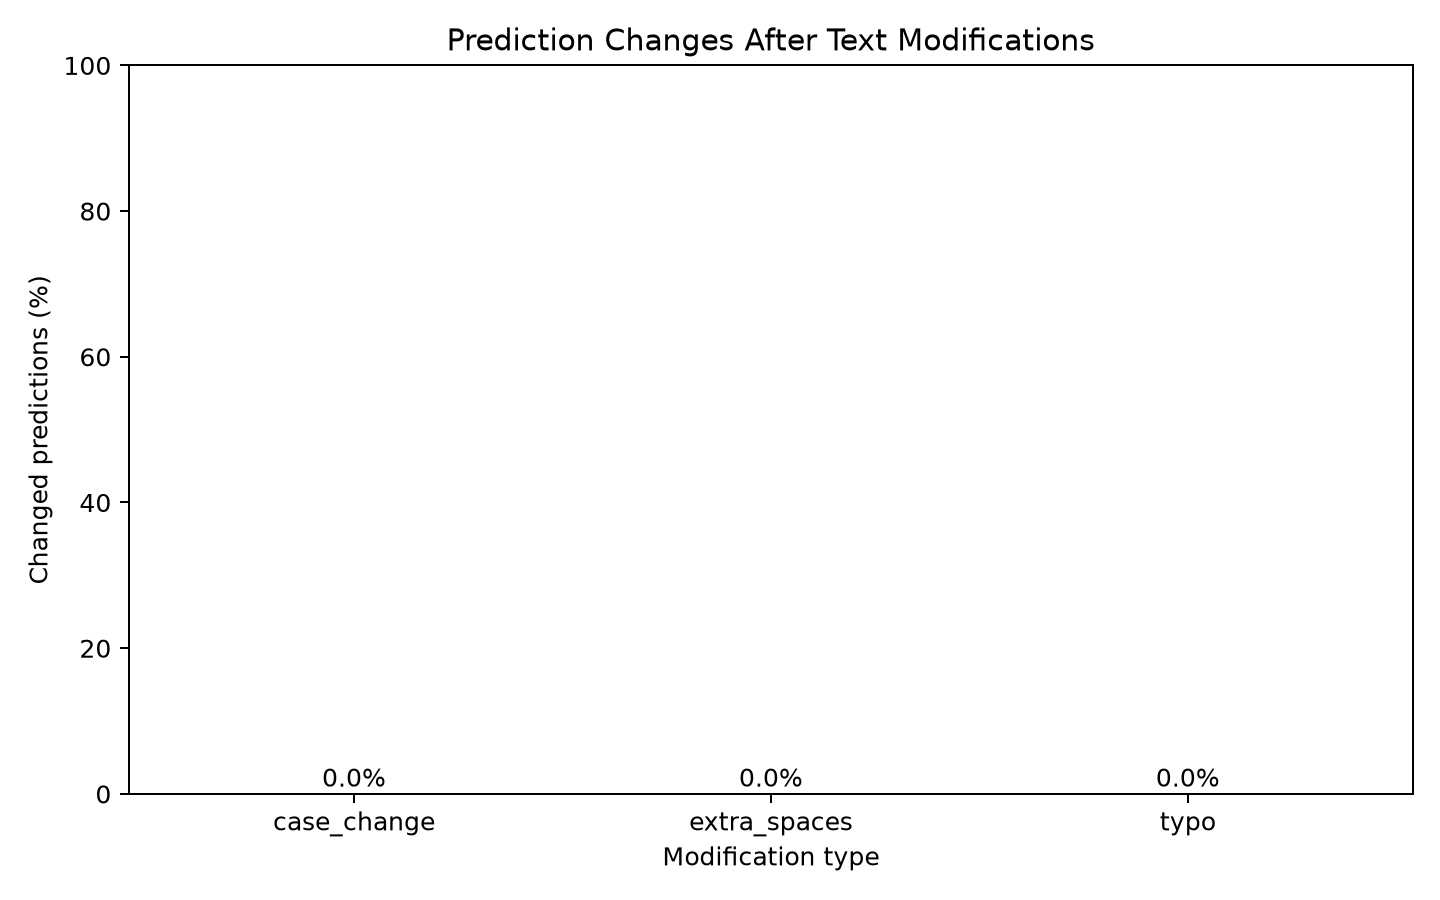

Нетипичный вход:
{
    "description": "Unusually long repetitive input",
    "length": 1079,
    "max_train_length": 627,
    "prediction": {
        "label": 0,
        "class_name": "BENIGN"
    }
}


In [8]:
display(
    Image(filename="../metrics/robustness_plot.png")
)

print("Нетипичный вход:")
print(json.dumps(
    robustness["unusual_input"],
    indent=4,
    ensure_ascii=False
))

## Выводы по лабораторной работе

В ходе лабораторной работы была разработана базовая модель обнаружения prompt injection-атак с использованием TF-IDF и Logistic Regression.

Для обучения использовалась подготовленная выборка из 11 050 текстовых запросов. Валидационная выборка содержала 1 981 объект, тестовая — 2 101 объект.

Перед обучением были устранены полные дубликаты, противоречивые метки и точные пересечения между выборками. Всего исключено 159 объектов. Исходные данные сохранены без изменений, их целостность контролируется с помощью SHA256.

На валидационной выборке модель достигла Accuracy 97,83% и F1-score 97,70% для класса INJECTION.

На тестовой выборке Accuracy составила 95,53%, Precision — 99,08%, Recall — 91,91%, F1-score — 95,36%.

Анализ матрицы ошибок показал 9 ложноположительных и 85 ложноотрицательных срабатываний. Пропущенные атаки представляют особый риск для безопасности LLM-систем.

Для защиты модели была реализована единая функция предсказания с проверкой типа, структуры и длины входных данных. Все 9 автоматических тестов pytest завершились успешно.

Эксперимент с устойчивостью на 20 запросах показал, что изменение регистра, добавление пробелов и небольшие опечатки не изменили предсказания модели. Однако небольшой объем эксперимента не позволяет распространить данный результат на все возможные атаки.

Статический анализ Bandit первоначально выявил три замечания B101, связанные с использованием assert. После замены этих конструкций явными проверками повторный анализ не обнаружил проблем.

Дополнительно проверены локальная привязка JupyterLab, защита доступа к API, права доступа к модели и целостность сохраненного артефакта.

Таким образом, разработана воспроизводимая базовая ML-модель с механизмами валидации входов и проведены первоначальные проверки ее безопасности и устойчивости. В дальнейшем необходимо исследовать способы сокращения количества пропущенных атак и устойчивость к более сложным изменениям текста.